# Out-of-sample and walk-forward testing

A backtest tuned on the same data it's scored on is flattering. These tests keep data back:

* **Out-of-sample**: search the parameter grid on the first part of the data, then trade the best settings, unchanged, on the rest.
* **Walk-forward**: do that repeatedly. Before each test window, re-tune on the training window just before it, then chain all the test windows into one out-of-sample result.

Change the settings in the next cell, then **Run All**. The walk-forward cell takes about 30 seconds on 5-minute bars with the default grid.

In [ ]:
TIMEFRAME = "5min"
GRID = {"fast": [5, 10, 20, 30, 50], "slow": [50, 100, 150, 200]}
OBJECTIVE = "sharpe"   # sharpe, sortino, net_pnl, return_pct, profit_factor, calmar, expectancy
MIN_TRADES = 10        # settings with fewer in-sample trades rank last
SPLIT = 0.7            # out-of-sample: fraction of bars that are in-sample
WINDOWS = 4            # walk-forward: test windows
TRAIN = 0.5            # walk-forward: fraction of bars in the first training window
ANCHORED = False       # walk-forward: training always starts at the first bar

# Same order / sizing / slippage options as the backtest notebook (pips; None = off)
STOP_LOSS, TAKE_PROFIT, TRAILING_STOP = None, None, None
SIZING, RISK_PCT = "fixed", 1.0   # "fixed" or "risk"
SLIPPAGE = 0

In [ ]:
%matplotlib inline
import pandas as pd
from backtest_engine import point_size
from backtest_engine.broker import FixedSlippage
from backtest_engine.data_loader import DEFAULT_FILE, MT5_SERVER_TZ, load_ohlcv, resample_ohlcv
from backtest_engine.optimize import RunConfig, out_of_sample, walk_forward
from backtest_engine.orders import OrderPolicy
from backtest_engine.sizing import RiskPercent

df = load_ohlcv(DEFAULT_FILE, tz=MT5_SERVER_TZ)
df = df if TIMEFRAME == "1min" else resample_ohlcv(df, TIMEFRAME)
point = point_size(df["close"].median())
config = RunConfig(
    symbol="USDJPY", point=point,
    sizer=RiskPercent(pct=RISK_PCT) if SIZING == "risk" else None,
    orders=OrderPolicy(stop_loss_pips=STOP_LOSS, take_profit_pips=TAKE_PROFIT, trailing_stop_pips=TRAILING_STOP),
    slippage=FixedSlippage(SLIPPAGE) if SLIPPAGE else None,
)
print(f"{len(df):,} bars from {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}")

20,022 bars from 2025-12-17 to 2026-03-27


## Out-of-sample

In [ ]:
oos = out_of_sample(df, GRID, config, split=SPLIT, objective=OBJECTIVE, min_trades=MIN_TRADES)
print(f"Chosen on in-sample (before {oos.split:%Y-%m-%d %H:%M} UTC): {oos.params}")
oos.table.head(10).style.format(precision=2).set_caption(f"In-sample parameter search, best {OBJECTIVE} first")

Chosen on in-sample (before 2026-02-26 07:00 UTC): {'fast': 10, 'slow': 100}


,fast,slow,score,trades,net_pnl,return_pct,sharpe,profit_factor,max_drawdown_pct,win_rate_pct
0,10,100,2.37,239,351.74,3.52,2.37,1.24,-3.85,28.87
1,20,100,0.89,199,144.61,1.45,0.89,1.10,-4.31,33.17
2,5,100,0.82,333,118.38,1.18,0.82,1.07,-4.07,25.83
3,10,50,0.70,368,97.59,0.98,0.70,1.05,-4.19,33.70
4,50,100,0.65,155,95.91,0.96,0.65,1.07,-3.89,41.94
5,50,200,0.58,91,83.10,0.83,0.58,1.07,-4.36,28.57
6,20,150,0.45,139,66.27,0.66,0.45,1.05,-2.93,30.22
7,20,200,0.15,127,17.68,0.18,0.15,1.01,-4.09,20.47
8,5,50,0.04,492,0.64,0.01,0.04,1.00,-4.72,28.86
9,50,150,-0.17,99,-33.54,-0.34,-0.17,0.97,-3.49,33.33


In [ ]:
oos.comparison().style.format("{:,.2f}").set_caption("Same settings: in-sample vs untouched out-of-sample")

,in_sample,out_of_sample
return_pct,3.52,-1.76
cagr_pct,19.56,-19.91
net_pnl,351.74,-175.70
max_drawdown_pct,-3.85,-2.39
sharpe,2.37,-2.50
profit_factor,1.24,0.77
win_rate_pct,28.87,24.30
trades,239.00,107.00
trades_per_day,4.78,4.86
expectancy,1.47,-1.64


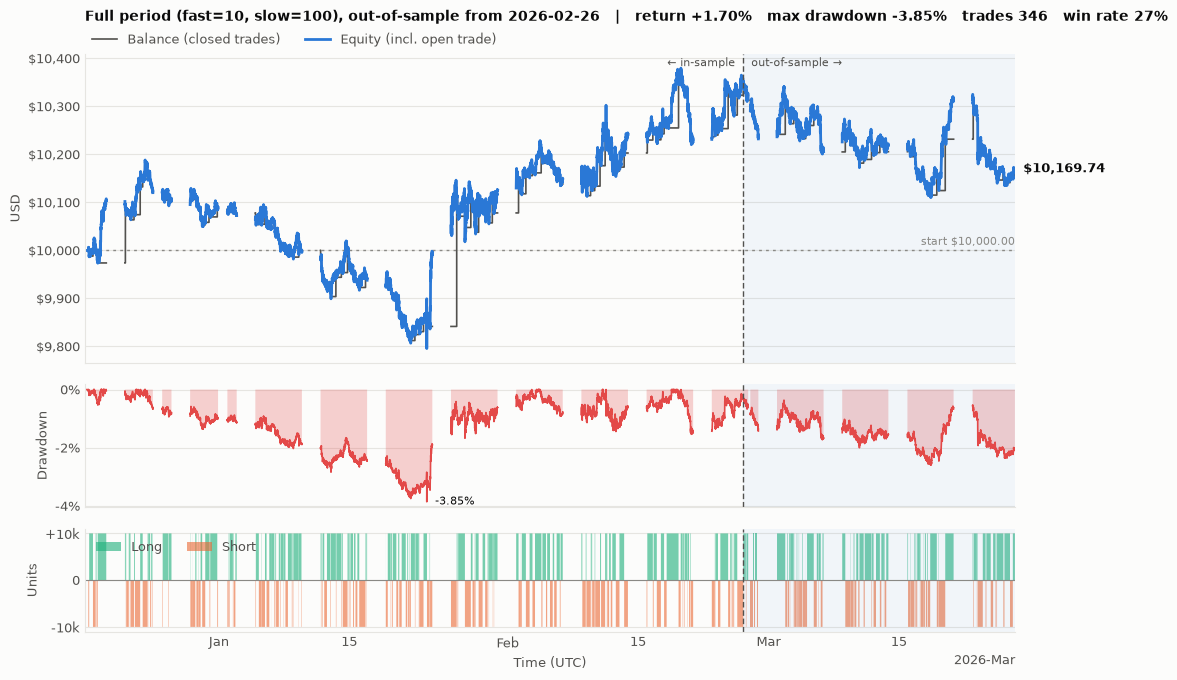

In [ ]:
oos.full.plot_equity()

## Walk-forward

In [ ]:
wf = walk_forward(df, GRID, config, windows=WINDOWS, train_frac=TRAIN, anchored=ANCHORED,
                  objective=OBJECTIVE, min_trades=MIN_TRADES)
cols = ["test_start", "test_end", *[c for c in wf.windows if c.startswith("param_")], "is_score",
        "is_return_pct", "oos_return_pct", "oos_net_pnl", "oos_trades", "oos_max_drawdown_pct", "oos_end_equity"]
wf.windows[cols].style.format({"test_start": "{:%Y-%m-%d}", "test_end": "{:%Y-%m-%d}", "is_score": "{:.2f}",
    "is_return_pct": "{:+.2f}%", "oos_return_pct": "{:+.2f}%", "oos_net_pnl": "${:,.2f}",
    "oos_max_drawdown_pct": "{:.2f}%", "oos_end_equity": "${:,.2f}"})

,test_start,test_end,param_fast,param_slow,is_score,is_return_pct,oos_return_pct,oos_net_pnl,oos_trades,oos_max_drawdown_pct,oos_end_equity
window,,,,,,,,,,,
1,2026-02-06,2026-02-19,50,100,2.26,+2.63%,-2.14%,$-214.17,28,-3.46%,"$9,785.83"
2,2026-02-19,2026-03-03,10,100,2.56,+2.68%,-0.75%,$-73.01,43,-1.63%,"$9,712.82"
3,2026-03-03,2026-03-16,10,100,2.40,+2.79%,-0.78%,$-75.82,47,-1.34%,"$9,637.00"
4,2026-03-16,2026-03-27,10,100,1.47,+1.50%,-0.14%,$-13.54,40,-1.94%,"$9,623.46"


In [ ]:
print(f"Walk-forward efficiency: {wf.efficiency:.2f}  (out-of-sample return per day / in-sample; ~0.5+ is encouraging)")
m = wf.combined.metrics()
m[m.section.isin(["Returns", "Risk"])].set_index("metric")[["display"]]

Walk-forward efficiency: -1.56  (out-of-sample return per day / in-sample; ~0.5+ is encouraging)


,display
metric,
Starting balance,"$10,000.00"
Final equity,"$9,623.46"
Net P&L,-$376.54
Return,-3.77%
Annualised return (CAGR),-24.85%
Gross profit,$988.38
Gross loss,"-$1,364.92"
Spread paid,$29.65
Slippage paid,$0.00


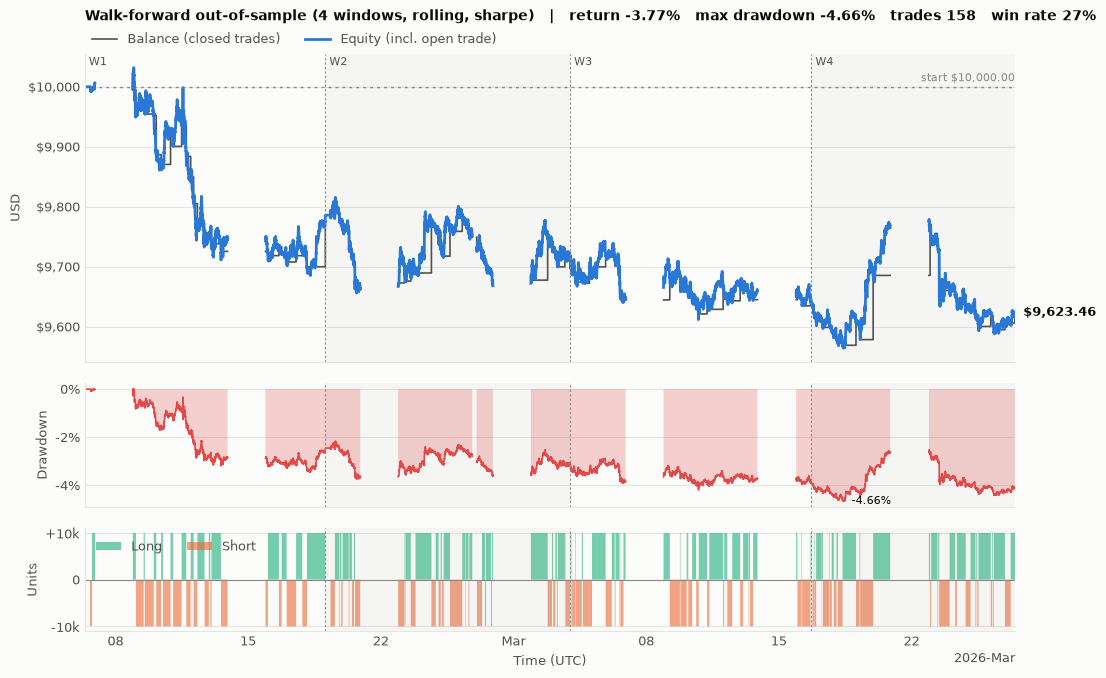

In [ ]:
wf.combined.plot_equity()

### Chained out-of-sample trade log

In [ ]:
wf.combined.trade_log().style.format(precision=3)

,side,entry_time,exit_time,duration,bars_held,units,entry_price,exit_price,pips,pnl,return_pct,spread_cost,slippage_cost,mae_pips,mfe_pips,balance,cum_pnl,exit_reason
trade,,,,,,,,,,,,,,,,,,
1,short,2026-02-06 16:20:00+00:00,2026-02-06 18:55:00+00:00,0 days 02:35:00,31,10000.000,156.991,157.064,-7.300,-4.648,-0.046,0.191,0.000,-14.200,2.400,9995.352,-4.648,signal
2,long,2026-02-06 18:55:00+00:00,2026-02-09 01:55:00+00:00,2 days 07:00:00,84,10000.000,157.064,156.637,-42.700,-27.260,-0.273,0.192,0.000,-84.600,59.500,9968.092,-31.908,signal
3,short,2026-02-09 01:55:00+00:00,2026-02-09 11:45:00+00:00,0 days 09:50:00,118,10000.000,156.637,156.513,12.360,7.897,0.079,0.217,0.000,-30.080,34.200,9975.989,-24.011,signal
4,long,2026-02-09 11:45:00+00:00,2026-02-09 13:10:00+00:00,0 days 01:25:00,17,10000.000,156.513,156.179,-33.440,-21.411,-0.215,0.218,0.000,-34.740,3.960,9954.577,-45.423,signal
5,short,2026-02-09 13:10:00+00:00,2026-02-10 00:30:00+00:00,0 days 11:20:00,136,10000.000,156.179,156.215,-3.620,-2.317,-0.023,0.205,0.000,-4.900,65.420,9952.260,-47.740,signal
6,long,2026-02-10 00:30:00+00:00,2026-02-10 03:40:00+00:00,0 days 03:10:00,38,10000.000,156.215,155.201,-101.420,-65.348,-0.657,0.206,0.000,-101.720,7.780,9886.913,-113.087,signal
7,short,2026-02-10 03:40:00+00:00,2026-02-10 09:50:00+00:00,0 days 06:10:00,74,10000.000,155.201,155.323,-12.200,-7.855,-0.079,0.193,0.000,-42.700,11.000,9879.058,-120.942,signal
8,long,2026-02-10 09:50:00+00:00,2026-02-10 12:10:00+00:00,0 days 02:20:00,28,10000.000,155.323,155.191,-13.200,-8.506,-0.086,0.193,0.000,-27.500,5.300,9870.552,-129.448,signal
9,short,2026-02-10 12:10:00+00:00,2026-02-10 21:45:00+00:00,0 days 09:35:00,115,10000.000,155.191,154.388,80.300,52.012,0.527,0.194,0.000,-11.800,113.440,9922.564,-77.436,signal
